# Dự đoán xu hướng giá nhà Phú Hòa (6–12 tháng tới)

**Mã sinh viên:** 2324801030095

**Họ và tên:** Nguyễn Quang Long

**Lớp:** D23KTPM01

> ⚠️ **Lưu ý quan trọng về dữ liệu.** Đề tài chỉ thu thập được dữ liệu tại **một thời điểm** (170 tin rao ngày 12/11/2026), nên không có lịch sử giá thật. Để xây dựng và minh họa được mô-đun dự báo xu hướng, notebook này **tạo dữ liệu lịch sử MÔ PHỎNG 2021–2026**: lấy giá thật quý 4/2026 làm mốc rồi lùi về quá khứ theo **các giả định ghi công khai ở Bước 1**.
>
> Vì vậy, con số "tăng/giảm" mà mô hình đưa ra **phản ánh các giả định mô phỏng, không phải dự báo thị trường thật**. Giá trị của notebook là **quy trình**: khi có dữ liệu lịch sử thật (thu thập định kỳ), chỉ cần thay tệp CSV ở Bước 1 là chạy lại được toàn bộ.

**Quy trình**
1. Tạo dữ liệu lịch sử mô phỏng (giao dịch theo quý, 2021–2026).
2. Khám phá dữ liệu theo thời gian.
3. Xây chỉ số giá hedonic theo phân khúc (tách ảnh hưởng của diện tích, số tầng… khỏi biến động thời gian).
4. Vì sao không đưa thẳng Năm/Quý vào mô hình cây để dự báo tương lai.
5. Xây tập học có giám sát: trạng thái thị trường tại quý *t* → % thay đổi sau 2 quý (6 tháng) và 4 quý (12 tháng).
6. Huấn luyện, so sánh Random Forest, LightGBM, XGBoost với baseline (chia theo thời gian).
7. Dự báo từ quý 4/2026, tính độ tin cậy, xuất JSON cho trang web.

In [1]:
# Mã sinh viên: 2324801030095
# Họ và tên: Nguyễn Quang Long
# Lớp: D23KTPM01
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.precision', 3)
plt.rcParams['figure.dpi'] = 100

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR, MODEL_DIR = Path('data'), Path('model')
REAL = pd.read_csv(DATA_DIR / 'nha_phu_hoa_da_xu_ly.csv')
RIDGE = json.load(open(MODEL_DIR / 'mo_hinh_gia_nha.json', encoding='utf-8'))
FEATURES = RIDGE['features']
print(f'Dữ liệu thật: {len(REAL)} căn, thu thập ngày {pd.read_csv(DATA_DIR / "nha_phu_hoa_guland_raw.csv")["ngay_thu_thap"].unique()}')
print('Đặc trưng của mô hình định giá:', FEATURES)

Dữ liệu thật: 170 căn, thu thập ngày <StringArray>
['2026-11-12']
Length: 1, dtype: str
Đặc trưng của mô hình định giá: ['dt_dat', 'mat_tien_x', 'so_tang_x', 'dt_san_x', 'phong_ngu_x', 'so_wc', 'vi_tri_cap', 'hem_rong_x', 'duong_ntmk', 'duong_lhp', 'noi_that_x']


## Bước 1. Tạo dữ liệu lịch sử mô phỏng 2021–2026

**Phân khúc** (đặc trưng tài sản quyết định tốc độ tăng giá):
- **Lối vào**: hẻm nhỏ (< 3,5 m) · hẻm xe hơi (3,5–10 m) · mặt đường — lấy từ `vi_tri_cap`.
- **Loại nhà**: nhà cấp 4 (≤ 1,5 tầng) · nhà phố (≥ 2 tầng) — lấy từ `so_tang_x`.

→ 3 × 2 = **6 phân khúc**. Ghi chú: đề xuất có đặc trưng *Phường*, nhưng dữ liệu chỉ có một phường (Phú Hòa) nên không dùng được.

**Giả định mô phỏng** (có thể sửa ở ô code dưới):
- **Chu kỳ thị trường chung** (% thay đổi giá mỗi quý): tăng mạnh 2021 – nửa đầu 2022 → điều chỉnh nhẹ, đi ngang 2023–2024 → phục hồi và tăng đều 2025–2026. Hình dạng này dựa trên diễn biến chung thường được nhắc tới của thị trường nhà đất, **các con số cụ thể là giả định, không phải thống kê chính thức**.
- **Mỗi phân khúc** có: độ nhạy với chu kỳ (beta), mức tăng riêng mỗi quý (drift) và nhiễu ngẫu nhiên có quán tính (AR(1)).
- **Giao dịch mỗi quý**: chọn ngẫu nhiên đặc điểm của một căn thật trong cùng phân khúc, thay đổi diện tích ±10%, rồi tính giá = **giá trị hedonic của căn đó năm 2026** (theo mô hình Ridge của notebook chính, nên giữ đúng mặt bằng giá thật) × (chỉ số quý đó ÷ chỉ số quý 4/2026) × nhiễu riêng từng căn (độ lệch chuẩn 12%).

In [2]:
QUARTERS = pd.period_range('2021Q1', '2026Q4', freq='Q')
T = len(QUARTERS)
# % thay đổi giá chung của thị trường mỗi quý (giả định)
MARKET_Q = [3.0, 3.5, 2.0, 3.5,      # 2021: tăng mạnh
            4.0, 3.0, 1.0, -1.5,     # 2022: tăng nóng nửa đầu năm rồi chững lại
            -2.0, -1.5, -1.0, -0.5,  # 2023: điều chỉnh nhẹ
            -0.5, 0.0, 0.5, 1.0,     # 2024: đi ngang, bắt đầu hồi
            1.5, 1.5, 2.0, 2.0,      # 2025: phục hồi
            2.0, 1.5, 1.5, 1.5]      # 2026: tăng đều
ACCESS = {'hem_nho': 'Hẻm nhỏ', 'hem_xe_hoi': 'Hẻm xe hơi', 'mat_duong': 'Mặt đường'}
TYPES = {'cap4': 'Nhà cấp 4', 'nha_pho': 'Nhà phố'}
BETA = {'hem_nho': 0.8, 'hem_xe_hoi': 1.0, 'mat_duong': 1.25}          # độ nhạy với chu kỳ
DRIFT = {'hem_nho': -0.35, 'hem_xe_hoi': 0.0, 'mat_duong': 0.45,       # %/quý riêng của lối vào
         'cap4': -0.25, 'nha_pho': 0.10}                                # %/quý riêng của loại nhà (nhà cũ xuống cấp)
AR_PHI, AR_SD = 0.5, 0.6            # nhiễu phân khúc: e_t = 0.5·e_(t-1) + N(0; 0,6%)
TX_PER_SEG, TX_NOISE = 150, 0.12     # số giao dịch mỗi phân khúc mỗi quý; nhiễu giá riêng từng căn (log)

display(pd.DataFrame({'Quý': QUARTERS.astype(str), 'Thị trường chung (%/quý)': MARKET_Q}).set_index('Quý').T)

Quý,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,...,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
Thị trường chung (%/quý),3.0,3.5,2.0,3.5,4.0,3.0,1.0,-1.5,-2.0,-1.5,...,0.5,1.0,1.5,1.5,2.0,2.0,2.0,1.5,1.5,1.5


In [3]:
def ridge_log_price(df):
    X = df[FEATURES].astype(float).to_numpy()
    med_, mu, sd = np.array(RIDGE['medians']), np.array(RIDGE['scaler']['mean']), np.array(RIDGE['scaler']['scale'])
    X = np.where(np.isnan(X), med_, X)
    return RIDGE['intercept'] + ((X - mu) / sd) @ np.array(RIDGE['coef'])

REAL['log_hedonic'] = ridge_log_price(REAL)   # giá trị hedonic 2026 của từng căn thật

def access_of(vt):
    if pd.isna(vt): return 'hem_xe_hoi'          # thiếu → nhóm phổ biến nhất
    return 'hem_nho' if vt <= 1 else ('mat_duong' if vt >= 5 else 'hem_xe_hoi')

def type_of(st):
    return 'cap4' if (not pd.isna(st)) and st <= 1.5 else 'nha_pho'

REAL['loi_vao'] = REAL['vi_tri_cap'].map(access_of)
REAL['loai_nha'] = REAL['so_tang_x'].map(type_of)
REAL['phan_khuc'] = REAL['loi_vao'] + '|' + REAL['loai_nha']
SEGMENTS = [f'{a}|{t}' for a in ACCESS for t in TYPES]
display(REAL['phan_khuc'].value_counts().reindex(SEGMENTS).to_frame('Số căn thật'))

# Chỉ số log của từng phân khúc theo quý (quý 4/2026 = 0)
seg_log_index = {}
for s in SEGMENTS:
    a, t = s.split('|')
    e, g = 0.0, []
    for q in range(T):
        e = AR_PHI * e + rng.normal(0, AR_SD)
        g.append((BETA[a] * MARKET_Q[q] + DRIFT[a] + DRIFT[t] + e) / 100)
    lvl = np.cumsum(g)
    seg_log_index[s] = lvl - lvl[-1]

rows = []
for q, per in enumerate(QUARTERS):
    for s in SEGMENTS:
        pool = REAL[REAL['phan_khuc'] == s]
        for _, r in pool.sample(TX_PER_SEG, replace=True, random_state=int(rng.integers(1e9))).iterrows():
            k = rng.uniform(0.9, 1.1)                         # thay đổi diện tích ±10%
            gia = np.exp(r['log_hedonic']) * k ** 0.85 * np.exp(seg_log_index[s][q] + rng.normal(0, TX_NOISE))
            month = (per.quarter - 1) * 3 + int(rng.integers(1, 4))
            row = {f: r[f] for f in FEATURES}
            row.update(dt_dat=round(r['dt_dat'] * k, 1), dt_san_x=(round(r['dt_san_x'] * k, 1) if pd.notna(r['dt_san_x']) else np.nan))
            row.update(ky=q, nam=per.year, quy=per.quarter, thang=month, phuong='Phú Hòa',
                       loi_vao=r['loi_vao'], loai_nha=r['loai_nha'], phan_khuc=s,
                       gia_ty=round(gia, 3), nguon='MO_PHONG')
            rows.append(row)
HIST = pd.DataFrame(rows)
HIST['don_gia_tr_m2'] = HIST['gia_ty'] * 1000 / HIST['dt_dat']
HIST.insert(0, 'ma_gd', range(1, len(HIST) + 1))
HIST.to_csv(DATA_DIR / 'lich_su_gia_mo_phong.csv', index=False, encoding='utf-8-sig')
print(f'Đã lưu data/lich_su_gia_mo_phong.csv: {HIST.shape[0]:,} giao dịch mô phỏng × {HIST.shape[1]} cột')
display(HIST.head())

,Số căn thật
phan_khuc,
hem_nho|cap4,12
hem_nho|nha_pho,9
hem_xe_hoi|cap4,47
hem_xe_hoi|nha_pho,69
mat_duong|cap4,11
mat_duong|nha_pho,22


Đã lưu data/lich_su_gia_mo_phong.csv: 21,600 giao dịch mô phỏng × 23 cột


,ma_gd,dt_dat,mat_tien_x,so_tang_x,dt_san_x,phong_ngu_x,so_wc,vi_tri_cap,hem_rong_x,duong_ntmk,...,nam,quy,thang,phuong,loi_vao,loai_nha,phan_khuc,gia_ty,nguon,don_gia_tr_m2
0,1,100.4,NaN,1.0,100.4,3.0,2.0,0.0,NaN,0,...,2021,1,1,Phú Hòa,hem_nho,cap4,hem_nho|cap4,2.699,MO_PHONG,26.882
1,2,259.5,8.0,1.0,259.5,NaN,NaN,1.0,3.0,1,...,2021,1,1,Phú Hòa,hem_nho,cap4,hem_nho|cap4,7.242,MO_PHONG,27.908
2,3,65.0,NaN,1.0,65.0,2.0,NaN,0.0,NaN,0,...,2021,1,3,Phú Hòa,hem_nho,cap4,hem_nho|cap4,1.861,MO_PHONG,28.631
3,4,92.2,NaN,1.0,92.2,3.0,2.0,0.0,NaN,0,...,2021,1,1,Phú Hòa,hem_nho,cap4,hem_nho|cap4,2.548,MO_PHONG,27.636
4,5,58.8,5.0,1.0,58.8,3.0,NaN,1.0,NaN,1,...,2021,1,1,Phú Hòa,hem_nho,cap4,hem_nho|cap4,2.822,MO_PHONG,47.993


## Bước 2. Khám phá dữ liệu theo thời gian

Đơn giá trung vị (triệu/m²) theo quý của từng phân khúc. Đơn giá thô còn chịu ảnh hưởng của việc mỗi quý lấy mẫu những căn khác nhau, nên đường khá nhấp nhô; Bước 3 sẽ loại bỏ phần này.

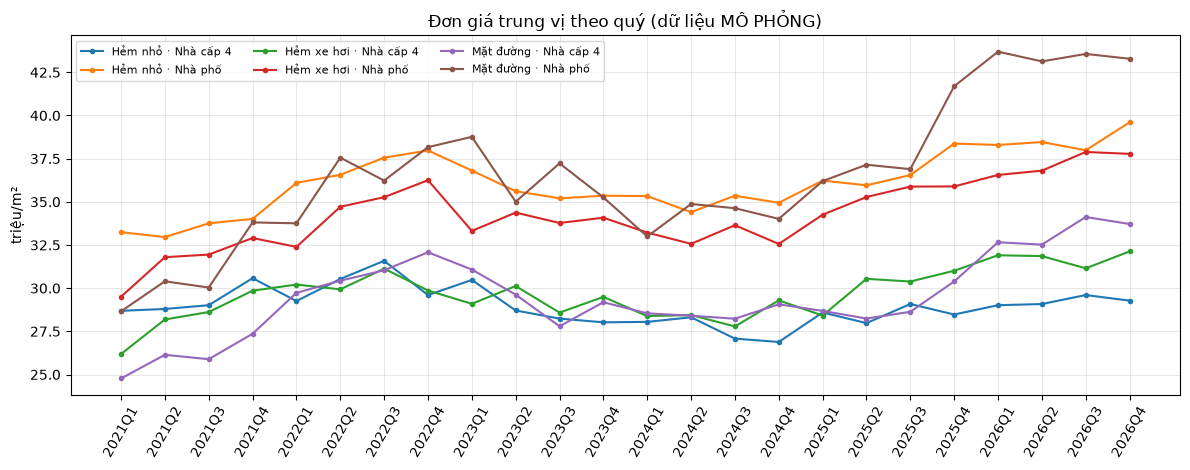

,so_giao_dich,don_gia_TV
nam,,
2021,3600,29.7
2022,3600,33.1
2023,3600,32.2
2024,3600,31.2
2025,3600,32.9
2026,3600,35.2


In [4]:
seg_name = lambda s: f"{ACCESS[s.split('|')[0]]} · {TYPES[s.split('|')[1]]}"
med = HIST.groupby(['ky', 'phan_khuc'])['don_gia_tr_m2'].median().unstack()[SEGMENTS]
fig, ax = plt.subplots(figsize=(12, 4.8))
for s in SEGMENTS:
    ax.plot(QUARTERS.astype(str), med[s], marker='o', ms=3, label=seg_name(s))
ax.set(title='Đơn giá trung vị theo quý (dữ liệu MÔ PHỎNG)', ylabel='triệu/m²')
ax.tick_params(axis='x', rotation=60); ax.legend(ncol=3, fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
display(HIST.groupby('nam').agg(so_giao_dich=('ma_gd', 'size'), don_gia_TV=('don_gia_tr_m2', 'median')).round(1))

## Bước 3. Chỉ số giá hedonic theo phân khúc

**Ý tưởng:** giá một căn = (giá do đặc điểm căn nhà quyết định) × (mức giá chung của thời điểm đó). Dùng chính **mô hình Ridge đã huấn luyện ở notebook chính** để ước tính phần thứ nhất cho từng giao dịch, phần còn lại là biến động theo thời gian:

$$\text{chỉ số}_{s,t} = \text{trung bình}\big[\log(\text{giá thực}) - \log(\text{giá Ridge})\big] \text{ trên các giao dịch của phân khúc } s \text{ trong quý } t$$

Chỉ số được quy về **quý 1/2021 = 100**. Cách này loại bỏ ảnh hưởng của việc quý này bán nhiều nhà lớn, quý kia bán nhiều nhà nhỏ.

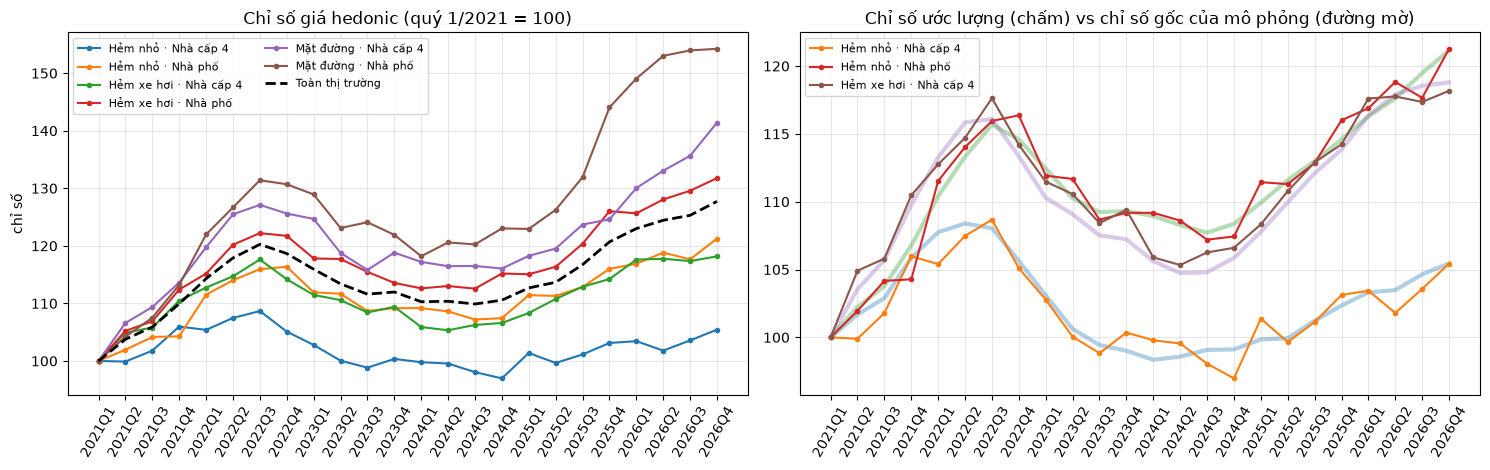

Thay đổi 4 quý: sai lệch TB giữa chỉ số ước lượng và gốc = 1.16 điểm %; độ lớn TB của thay đổi thật = 6.28 điểm %.
Tương quan giữa thay đổi ước lượng và thay đổi thật: 0.980
→ Sai lệch nhỏ hơn nhiều so với biến động: chỉ số theo dõi được xu hướng.


In [5]:
HIST['resid'] = np.log(HIST['gia_ty']) - ridge_log_price(HIST)
IDX = HIST.groupby(['ky', 'phan_khuc'])['resid'].mean().unstack()[SEGMENTS]
IDX = IDX - IDX.iloc[0]                                  # log, quý 1/2021 = 0
MKT = HIST.groupby('ky')['resid'].mean(); MKT = MKT - MKT.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for s in SEGMENTS:
    axes[0].plot(QUARTERS.astype(str), 100 * np.exp(IDX[s]), marker='o', ms=3, label=seg_name(s))
axes[0].plot(QUARTERS.astype(str), 100 * np.exp(MKT), 'k--', lw=2, label='Toàn thị trường')
axes[0].set(title='Chỉ số giá hedonic (quý 1/2021 = 100)', ylabel='chỉ số'); axes[0].legend(fontsize=8, ncol=2)
# Kiểm tra: chỉ số ước lượng có khớp với chỉ số đã dùng để mô phỏng không?
for s in SEGMENTS[:3]:
    true = seg_log_index[s] - seg_log_index[s][0]
    axes[1].plot(QUARTERS.astype(str), 100 * np.exp(true), lw=3, alpha=.35)
    axes[1].plot(QUARTERS.astype(str), 100 * np.exp(IDX[s]), marker='o', ms=3, label=seg_name(s))
axes[1].set(title='Chỉ số ước lượng (chấm) vs chỉ số gốc của mô phỏng (đường mờ)')
axes[1].legend(fontsize=8)
for ax in axes: ax.tick_params(axis='x', rotation=60); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
# Mô hình dùng thay đổi 4 quý (đà tăng/giảm), nên kiểm tra chỉ số trên chính đại lượng đó.
d4_est = np.concatenate([IDX[s].to_numpy()[4:] - IDX[s].to_numpy()[:-4] for s in SEGMENTS])
d4_true = np.concatenate([seg_log_index[s][4:] - seg_log_index[s][:-4] for s in SEGMENTS])
err4, move4 = np.abs(d4_est - d4_true).mean() * 100, np.abs(d4_true).mean() * 100
print(f'Thay đổi 4 quý: sai lệch TB giữa chỉ số ước lượng và gốc = {err4:.2f} điểm %; độ lớn TB của thay đổi thật = {move4:.2f} điểm %.')
print(f'Tương quan giữa thay đổi ước lượng và thay đổi thật: {np.corrcoef(d4_est, d4_true)[0, 1]:.3f}')
print('→ Sai lệch nhỏ hơn nhiều so với biến động: chỉ số theo dõi được xu hướng.' if err4 < move4 / 2 else '→ Sai lệch còn lớn so với biến động: chỉ số nhiễu, cần nhiều giao dịch hơn.')

## Bước 4. Vì sao không đưa thẳng Năm/Quý vào Random Forest để dự báo tương lai?

Cách "tự nhiên" là huấn luyện mô hình cây trên từng giao dịch với đặc trưng *(diện tích, số tầng, phòng ngủ, độ rộng hẻm, …, năm, quý)* rồi hỏi giá năm 2027. Nhưng **mô hình cây chia dữ liệu theo ngưỡng đã thấy**: mọi thời điểm sau quý 4/2026 đều rơi vào cùng một lá với quý 4/2026, nên dự báo **đứng yên** dù xu hướng đang tăng. Ô dưới chứng minh điều này.

In [6]:
TX_COLS = FEATURES + ['ky']
rf_tx = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
rf_tx.fit(HIST[TX_COLS], np.log(HIST['gia_ty']))
sample = REAL[FEATURES].iloc[[0]].copy()
preds = {QUARTERS[k].strftime('%YQ%q') if k < T else f'{2026 + (k - T) // 4 + 1}Q{(k - T) % 4 + 1}': float(np.exp(rf_tx.predict(sample.assign(ky=k))[0]))
         for k in [T - 8, T - 4, T - 2, T - 1, T, T + 2, T + 4]}
display(pd.DataFrame({'Giá dự đoán (tỷ)': preds}).T.round(3))
print('→ Từ 2027 trở đi giá đứng yên bằng quý 4/2026: mô hình cây KHÔNG ngoại suy được theo thời gian.')

,2025Q1,2026Q1,2026Q3,2026Q4,2027Q1,2027Q3,2028Q1
Giá dự đoán (tỷ),2.517,2.834,2.839,2.859,2.859,2.859,2.859


→ Từ 2027 trở đi giá đứng yên bằng quý 4/2026: mô hình cây KHÔNG ngoại suy được theo thời gian.


## Bước 5. Xây tập học có giám sát cho bài toán dự báo

Đổi cách đặt bài toán: thay vì hỏi "giá ở năm X là bao nhiêu", hỏi **"đứng ở quý *t*, giá phân khúc này sẽ thay đổi bao nhiêu % sau *h* quý?"**. Mỗi mẫu = (phân khúc *s*, quý gốc *t*):

| Đặc trưng | Ý nghĩa |
|---|---|
| `loi_vao`, `cap4` | đặc điểm tài sản của phân khúc |
| `quy` | quý trong năm (mùa vụ) |
| `mom1`, `mom2`, `mom4` | % thay đổi chỉ số phân khúc trong 1, 2, 4 quý gần nhất (đà tăng/giảm) |
| `mkt_mom4` | % thay đổi chung của thị trường trong 4 quý |
| `lech_tb4` | chỉ số hiện tại lệch bao nhiêu so với trung bình 4 quý (đang ở đỉnh hay đáy) |

**Nhãn:** $y_h = \text{chỉ số}_{s,t+h} - \text{chỉ số}_{s,t}$ (log ≈ %), với *h* = 2 quý (6 tháng) và *h* = 4 quý (12 tháng). Đặc trưng chỉ dùng thông tin **đến quý *t***, nên không rò rỉ tương lai.

In [7]:
ACC_CODE = {'hem_nho': 0, 'hem_xe_hoi': 1, 'mat_duong': 2}
FEAT_TS = ['loi_vao', 'cap4', 'quy', 'mom1', 'mom2', 'mom4', 'mkt_mom4', 'lech_tb4']

def state(s, t):
    I = IDX[s].to_numpy(); M = MKT.to_numpy(); a, ty = s.split('|')
    return {'phan_khuc': s, 'ky': t, 'loi_vao': ACC_CODE[a], 'cap4': int(ty == 'cap4'), 'quy': QUARTERS[t].quarter,
            'mom1': I[t] - I[t - 1], 'mom2': I[t] - I[t - 2], 'mom4': I[t] - I[t - 4],
            'mkt_mom4': M[t] - M[t - 4], 'lech_tb4': I[t] - I[t - 3:t + 1].mean()}

def make_dataset(h):
    out = []
    for s in SEGMENTS:
        for t in range(4, T - h):
            r = state(s, t); r['y'] = IDX[s].iloc[t + h] - IDX[s].iloc[t]; out.append(r)
    return pd.DataFrame(out)

DS = {h: make_dataset(h) for h in (2, 4)}
for h, d in DS.items():
    print(f'h = {h} quý: {len(d)} mẫu, quý gốc {QUARTERS[d.ky.min()]} → {QUARTERS[d.ky.max()]}')
display(DS[4].head())

h = 2 quý: 108 mẫu, quý gốc 2022Q1 → 2026Q2
h = 4 quý: 96 mẫu, quý gốc 2022Q1 → 2025Q4


,phan_khuc,ky,loi_vao,cap4,quy,mom1,mom2,mom4,mkt_mom4,lech_tb4,y
0,hem_nho|cap4,4,0,1,1,-0.005,0.035,0.053,0.134,0.021,-0.025
1,hem_nho|cap4,5,0,1,2,0.020,0.014,0.073,0.128,0.022,-0.072
2,hem_nho|cap4,6,0,1,3,0.011,0.031,0.065,0.127,0.017,-0.095
3,hem_nho|cap4,7,0,1,4,-0.033,-0.022,-0.008,0.076,-0.015,-0.046
4,hem_nho|cap4,8,0,1,1,-0.022,-0.056,-0.025,0.014,-0.031,-0.030


## Bước 6. Huấn luyện và so sánh mô hình (chia theo thời gian)

**Chia train/test theo thời gian:** 4 quý gốc cuối cùng làm tập kiểm tra, các quý trước làm tập huấn luyện. Không chia ngẫu nhiên vì như vậy mô hình được "nhìn trước" tương lai.

**Hai baseline** để biết mô hình học máy có thật sự hữu ích:
- *Không đổi*: dự đoán giá giữ nguyên (0%).
- *Theo đà*: tốc độ 4 quý gần nhất tiếp tục, `mom4 × h/4`.

**Chỉ số đánh giá:** MAE (điểm %) và **độ chính xác chiều** (đoán đúng tăng hay giảm).

In [8]:
def models():
    return {
        'Random Forest': RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.6, random_state=SEED, n_jobs=-1),
        'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=5, subsample=0.8, subsample_freq=1, random_state=SEED, verbose=-1),
        'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=SEED),
    }

RESULTS, TEST_RMSE = [], {}
for h, d in DS.items():
    cut = d.ky.max() - 3
    tr, te = d[d.ky < cut], d[d.ky >= cut]
    preds = {'Baseline: không đổi': np.zeros(len(te)), 'Baseline: theo đà': te['mom4'].to_numpy() * h / 4}
    for name, m in models().items():
        preds[name] = m.fit(tr[FEAT_TS], tr['y']).predict(te[FEAT_TS])
    for name, p in preds.items():
        RESULTS.append({'Kỳ hạn': f'{h * 3} tháng', 'Mô hình': name, 'MAE (điểm %)': mean_absolute_error(te['y'], p) * 100,
                        'Đúng chiều (%)': np.nan if name == 'Baseline: không đổi' else np.mean(np.sign(p) == np.sign(te['y'])) * 100, 'Số mẫu test': len(te)})
        TEST_RMSE[(h, name)] = float(np.sqrt(np.mean((te['y'] - p) ** 2)))
RES = pd.DataFrame(RESULTS)
display(RES.round(2).set_index(['Kỳ hạn', 'Mô hình']))

MAE (điểm %)  Đúng chiều (%)  Số mẫu test
Kỳ hạn   Mô hình                                                       
6 tháng  Baseline: không đổi          3.31             NaN           24
         Baseline: theo đà            2.51           91.67           24
         Random Forest                4.01           29.17           24
         LightGBM                     4.80           37.50           24
         XGBoost                      3.99           50.00           24
12 tháng Baseline: không đổi          7.64             NaN           24
         Baseline: theo đà            5.00          100.00           24
         Random Forest               12.48            0.00           24
         LightGBM                    13.73            0.00           24
         XGBoost                     12.61            0.00           24

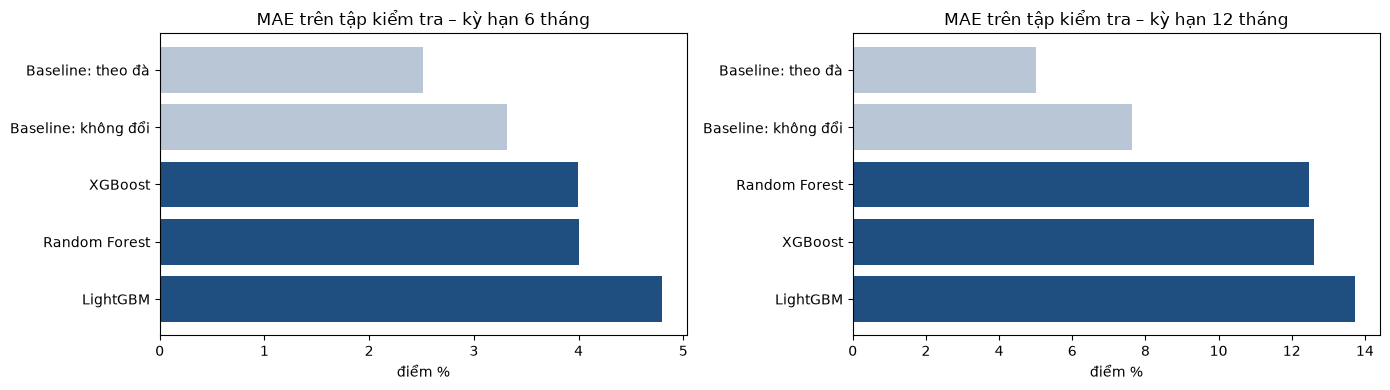

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (k, g) in zip(axes, RES.groupby('Kỳ hạn', sort=False)):
    g = g.sort_values('MAE (điểm %)')
    ax.barh(g['Mô hình'], g['MAE (điểm %)'], color=['#1f4f80' if 'Baseline' not in n else '#b9c6d6' for n in g['Mô hình']])
    ax.invert_yaxis(); ax.set(title=f'MAE trên tập kiểm tra – kỳ hạn {k}', xlabel='điểm %')
plt.tight_layout(); plt.show()

**Chọn phương án cuối:** với mỗi kỳ hạn, chọn phương án có **MAE thấp nhất trên tập kiểm tra, kể cả baseline**. Nếu một baseline đơn giản thắng thì mô hình học máy không đáng dùng ở kỳ hạn đó, và báo cáo phải nói rõ điều này.

In [10]:
CHOICE = {}
for h in (2, 4):
    g = RES[RES['Kỳ hạn'] == f'{h * 3} tháng'].set_index('Mô hình')['MAE (điểm %)']
    CHOICE[h] = g.idxmin()
    ml_best = g.drop([i for i in g.index if 'Baseline' in i]).idxmin()
    base_best = min(g['Baseline: theo đà'], g['Baseline: không đổi'])
    print(f'Kỳ hạn {h * 3} tháng: chọn {CHOICE[h]} (MAE {g[CHOICE[h]]:.2f}). Mô hình học máy tốt nhất: {ml_best} ({g[ml_best]:.2f}); '
          f'baseline tốt nhất: {base_best:.2f} → học máy {"tốt hơn" if g[ml_best] < base_best else "KHÔNG tốt hơn"} baseline '
          f'({(1 - g[ml_best] / base_best) * 100:+.0f}% sai số).')

Kỳ hạn 6 tháng: chọn Baseline: theo đà (MAE 2.51). Mô hình học máy tốt nhất: XGBoost (3.99); baseline tốt nhất: 2.51 → học máy KHÔNG tốt hơn baseline (-59% sai số).
Kỳ hạn 12 tháng: chọn Baseline: theo đà (MAE 5.00). Mô hình học máy tốt nhất: Random Forest (12.48); baseline tốt nhất: 5.00 → học máy KHÔNG tốt hơn baseline (-150% sai số).


**Đọc kết quả.** Ở lần chạy này, các mô hình cây **thua baseline "theo đà"** và đoán sai chiều trên tập kiểm tra (giai đoạn phục hồi 2025–2026). Nguyên nhân: dữ liệu chỉ có **một chu kỳ** thị trường. Trong tập huấn luyện, giai đoạn tăng mạnh 2021–2022 được nối tiếp bởi điều chỉnh 2023, nên mô hình học được quy luật "đà tăng cao → sắp giảm" và áp sai quy luật đó vào giai đoạn phục hồi. Đây là hạn chế thường gặp của dự báo chuỗi thời gian khi lịch sử ngắn (thị trường đổi chế độ). Vì vậy quy trình **luôn so với baseline** và tự chọn phương án tốt hơn; muốn mô hình học máy có ích cần lịch sử dài hơn, gồm nhiều chu kỳ.

## Bước 7. Dự báo từ quý 4/2026 và độ tin cậy

Huấn luyện lại mô hình đã chọn trên **toàn bộ** mẫu rồi dự báo cho trạng thái quý 4/2026 của từng phân khúc.

**Độ tin cậy** kết hợp hai nguồn không chắc chắn:
- độ phân tán dự đoán giữa các cây, nếu phương án được chọn là mô hình nhiều cây (Random Forest), và
- sai số RMSE trên tập kiểm tra (mô hình đã từng sai bao nhiêu).

Gộp thành độ lệch chuẩn $\sigma = \sqrt{\sigma_{cây}^2 + \text{RMSE}^2}$, giả sử phân phối chuẩn: $P(\text{tăng}) = \Phi(\hat{y} / \sigma)$. **Độ tin cậy về chiều** = $\max(P(\text{tăng}), 1 - P(\text{tăng}))$. Khoảng dự báo 80% = $\hat{y} \pm 1{,}28\sigma$.

In [11]:
from math import erf, sqrt
Phi = lambda z: 0.5 * (1 + erf(z / sqrt(2)))
FORECAST = {s: {} for s in SEGMENTS}
for h, d in DS.items():
    name = CHOICE[h]; X_now = pd.DataFrame([state(s, T - 1) for s in SEGMENTS]); tree_sd = np.zeros(len(SEGMENTS))
    if name == 'Baseline: theo đà': yhat = X_now['mom4'].to_numpy() * h / 4
    elif name == 'Baseline: không đổi': yhat = np.zeros(len(SEGMENTS))
    else:
        m = models()[name].fit(d[FEAT_TS], d['y']); yhat = m.predict(X_now[FEAT_TS])
        if name == 'Random Forest': tree_sd = np.std([t.predict(X_now[FEAT_TS].to_numpy()) for t in m.estimators_], axis=0)
    sd = np.sqrt(tree_sd ** 2 + TEST_RMSE[(h, name)] ** 2)
    for s, y, sg in zip(SEGMENTS, yhat, sd):
        p_up = min(max(Phi(y / sg), 0.01), 0.99)   # không báo chắc chắn tuyệt đối khi tập kiểm tra nhỏ
        FORECAST[s][f'h{h}'] = {'pct': (np.exp(y) - 1) * 100, 'lo': (np.exp(y - 1.28 * sg) - 1) * 100, 'hi': (np.exp(y + 1.28 * sg) - 1) * 100,
                                'p_up': p_up, 'conf': max(p_up, 1 - p_up), 'model': name}
tbl = pd.DataFrame([{'Phân khúc': seg_name(s), **{f'{k} {h[1:]}q': v[k] for h, v in FORECAST[s].items() for k in ('pct', 'lo', 'hi', 'conf')}} for s in SEGMENTS]).set_index('Phân khúc')
display(tbl.round(2))

,pct 2q,lo 2q,hi 2q,conf 2q,pct 4q,lo 4q,hi 4q,conf 4q
Phân khúc,,,,,,,,
Hẻm nhỏ · Nhà cấp 4,1.12,-3.13,5.55,0.63,2.24,-5.73,10.90,0.64
Hẻm nhỏ · Nhà phố,2.25,-2.05,6.73,0.75,4.54,-3.62,13.39,0.76
Hẻm xe hơi · Nhà cấp 4,1.71,-2.56,6.17,0.69,3.45,-4.62,12.21,0.70
Hẻm xe hơi · Nhà phố,2.25,-2.04,6.73,0.75,4.56,-3.60,13.41,0.76
Mặt đường · Nhà cấp 4,6.53,2.06,11.20,0.97,13.49,4.63,23.10,0.98
Mặt đường · Nhà phố,3.48,-0.87,8.01,0.85,7.07,-1.28,16.14,0.86


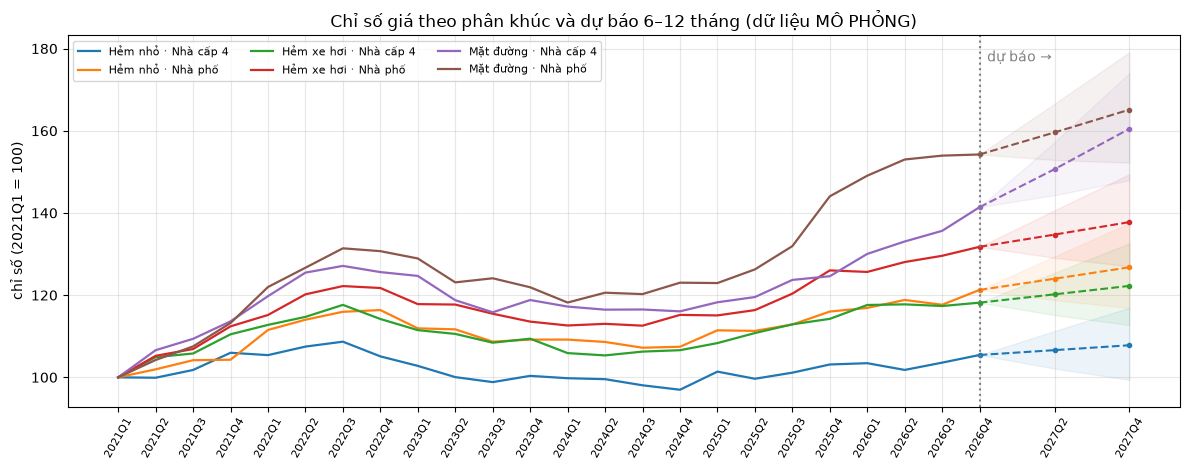

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.8))
x = list(range(T)); lab = list(QUARTERS.astype(str)) + ['2027Q2', '2027Q4']
for i, s in enumerate(SEGMENTS):
    c = plt.cm.tab10(i); base = 100 * np.exp(IDX[s].iloc[-1])
    ax.plot(x, 100 * np.exp(IDX[s]), color=c, lw=1.6, label=seg_name(s))
    f = FORECAST[s]
    ax.plot([T - 1, T + 1, T + 3], [base, base * (1 + f['h2']['pct'] / 100), base * (1 + f['h4']['pct'] / 100)], '--o', color=c, ms=3)
    ax.fill_between([T - 1, T + 1, T + 3], [base, base * (1 + f['h2']['lo'] / 100), base * (1 + f['h4']['lo'] / 100)],
                    [base, base * (1 + f['h2']['hi'] / 100), base * (1 + f['h4']['hi'] / 100)], color=c, alpha=.08)
ax.axvline(T - 1, color='gray', ls=':'); ax.text(T - 0.8, ax.get_ylim()[1] * 0.98, 'dự báo →', va='top', color='gray')
ax.set_xticks(list(range(T)) + [T + 1, T + 3]); ax.set_xticklabels(lab, rotation=60, fontsize=8)
ax.set(title='Chỉ số giá theo phân khúc và dự báo 6–12 tháng (dữ liệu MÔ PHỎNG)', ylabel='chỉ số (2021Q1 = 100)')
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

In [13]:
# Xuất cho trang web: lịch sử chỉ số, dự báo, độ tin cậy, kết quả so sánh mô hình và giả định mô phỏng.
export = {
    'nguon_du_lieu': 'MO_PHONG', 'ghi_chu': 'Lịch sử giá 2021–2026 là dữ liệu mô phỏng theo giả định; dự báo phản ánh giả định, không phải dự báo thị trường thật.',
    'quarters': list(QUARTERS.astype(str)), 'gia_dinh_thi_truong_pct_quy': MARKET_Q,
    'segments': {s: {'ten': seg_name(s), 'chi_so': (100 * np.exp(IDX[s])).round(2).tolist(),
                     'h2': {k: round(float(v), 4) if k != 'model' else v for k, v in FORECAST[s]['h2'].items()},
                     'h4': {k: round(float(v), 4) if k != 'model' else v for k, v in FORECAST[s]['h4'].items()}} for s in SEGMENTS},
    'danh_gia': RES.round(3).to_dict('records'), 'mo_hinh_chon': {f'h{h}': CHOICE[h] for h in CHOICE},
    'so_giao_dich_mo_phong': int(len(HIST)),
}
json.dump(export, open(MODEL_DIR / 'xu_huong_gia.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('Đã lưu model/xu_huong_gia.json')

Đã lưu model/xu_huong_gia.json


## Kết luận

- Mô-đun dự báo xu hướng gồm: dữ liệu giao dịch theo quý → **chỉ số giá hedonic** theo phân khúc → mô hình học máy dự đoán **% thay đổi sau 6 và 12 tháng** từ đà tăng/giảm gần nhất và đặc điểm phân khúc → **độ tin cậy** kết hợp độ phân tán giữa các cây và sai số kiểm định.
- Bước 4 cho thấy một lỗi thiết kế phổ biến: đưa trực tiếp Năm/Quý vào mô hình cây thì **không dự báo được tương lai** (giá đứng yên).
- Bảng ở Bước 6 cần đọc cùng baseline: mô hình học máy chỉ đáng dùng khi tốt hơn rõ rệt so với "không đổi" và "theo đà". Với lịch sử chỉ một chu kỳ, baseline "theo đà" thắng cả hai kỳ hạn.

**Hạn chế (cần nêu khi trình bày)**
- **Lịch sử giá là mô phỏng.** Mô hình học lại chính các giả định ở Bước 1, nên kết quả dự báo minh họa quy trình, **không** phải nhận định thị trường Phú Hòa.
- Chỉ có 6 phân khúc × 20 quý nên số mẫu học rất ít; với dữ liệu thật cần nhiều quý hơn.
- **Hướng phát triển:** chạy script thu thập định kỳ (mỗi tuần/tháng), ghép các đợt thành tệp có cùng cấu trúc `lich_su_gia_mo_phong.csv` (cột `nguon` = tên nguồn thật), chạy lại notebook này.